Dataset shape: (4998, 141)
        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138

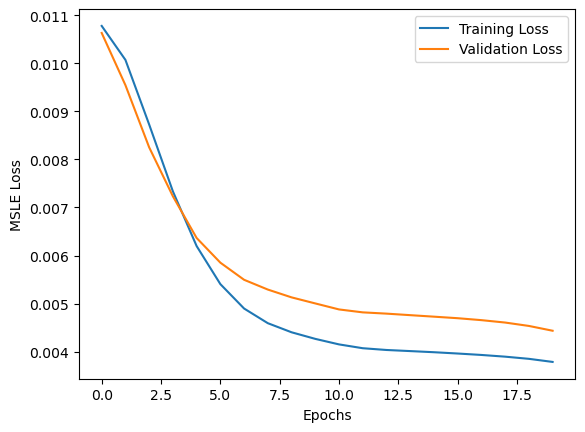

Threshold: 0.0087488815
Accuracy: 0.947
Number of anomalies: 461


In [3]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers, models


# Load dataset
df = pd.read_csv("ecg.csv", header=None)

print("Dataset shape:", df.shape)
print(df.head())


# Separate features and labels
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

x_train = x_train[y_train == 1]

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)


# Feature scaling
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


# Build Encoder
encoder = models.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu")
])


# Build Decoder
decoder = models.Sequential([
    layers.Input(shape=(8,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(x_train.shape[1], activation="sigmoid")
])

model = models.Sequential([encoder, decoder])


# Compile and train model
model.compile(
    optimizer="adam",
    loss="mean_squared_logarithmic_error",
    metrics=["mse"]
)

history = model.fit(
    x_train, x_train,
    validation_split=0.1,
    epochs=20,
    batch_size=512
)


# Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSLE Loss")
plt.legend()
plt.show()


# Calculate threshold using training data
predictions = model.predict(x_train, verbose=0)
errors = tf.keras.losses.msle(x_train, predictions).numpy()

threshold = np.mean(errors) + np.std(errors)


# Detect anomalies in test data
predictions = model.predict(x_test, verbose=0)
errors = tf.keras.losses.msle(x_test, predictions).numpy()

anomalies = (errors > threshold).astype(int)
y_pred = 1 - anomalies

print("Threshold:", threshold)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Number of anomalies:", np.sum(anomalies))